In [1]:
import os, random, hashlib, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

DEBUG      = True    # True = tiny CPU dry run. Set False for the real run.
CHANNELS   = 1       # 1 = grayscale, 3 = RGB
IMG_SIZE   = 128
BATCH_SIZE = 64
EPOCHS     = 2 if DEBUG else 40
LR, WEIGHT_DECAY, PATIENCE, SEED = 2e-3, 1e-2, 8, 42
RUN_NAME   = f"cnn_{'gray' if CHANNELS == 1 else 'rgb'}{'_debug' if DEBUG else ''}"
OUT_DIR    = Path('/kaggle/working')

CLASSES = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| DEBUG:', DEBUG, '| CHANNELS:', CHANNELS)

Device: cpu | DEBUG: True | CHANNELS: 1


In [2]:
INPUT = Path('/kaggle/input')
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
imgs = sorted(p for p in INPUT.rglob('*') if p.suffix.lower() in EXT)
csvs = sorted(INPUT.rglob('*.csv'))
print(len(imgs), 'images | CSVs:', [str(c) for c in csvs])

def norm(s): return str(s).strip().lower().rstrip('s')      # treats DogEye / DogEyes as the same
CANON = {norm(c): c for c in CLASSES}
def in_test(p): return any('test' in part.lower() for part in p.relative_to(INPUT).parts[1:-1])

test_paths = [p for p in imgs if in_test(p)]
train_imgs = [p for p in imgs if not in_test(p)]
sample_sub = next((c for c in csvs if 'sample' in c.name.lower() or 'submission' in c.name.lower()), None)
label_csv  = next((c for c in csvs if c != sample_sub and 'test' not in c.name.lower()), None)

if all(norm(p.parent.name) in CANON for p in train_imgs[:50]):
    print('Layout: class subfolders')
    train_df = pd.DataFrame({'path': train_imgs, 'label': [CANON[norm(p.parent.name)] for p in train_imgs]})
else:
    print('Layout: CSV labels ->', label_csv)
    lab = pd.read_csv(label_csv, dtype=str); print(lab.head(3))
    id_col  = 'image_id' if 'image_id' in lab.columns else lab.columns[0]
    cls_col = 'class' if 'class' in lab.columns else lab.columns[-1]
    s2p = {p.stem: p for p in train_imgs}
    lab['path'] = lab[id_col].map(lambda i: s2p.get(Path(str(i)).stem))
    lab = lab.dropna(subset=['path'])
    train_df = pd.DataFrame({'path': lab['path'], 'label': lab[cls_col].map(lambda s: CANON[norm(s)])})
train_df = train_df.reset_index(drop=True)

# order test images exactly like the sample submission
test_ids = [p.stem for p in test_paths]
if sample_sub is not None:
    ss = pd.read_csv(sample_sub, dtype=str)
    t2p = {p.stem: p for p in test_paths}
    test_ids = [i for i in ss.iloc[:, 0] if i in t2p]
    test_paths = [t2p[i] for i in test_ids]
    print('Sample submission class values seen:', ss.iloc[:, 1].unique()[:10])
print(f'Train {len(train_df)} | Test {len(test_paths)} | matched to sample sub: {sample_sub is not None}')
print(train_df['label'].value_counts())

93103 images | CSVs: ['/kaggle/input/datasets/iylabl/facial-feature-classification-challenge/sample_submission.csv', '/kaggle/input/datasets/iylabl/facial-feature-classification-challenge/train_labels.csv']
Layout: CSV labels -> /kaggle/input/datasets/iylabl/facial-feature-classification-challenge/train_labels.csv
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
Sample submission class values seen: ['DogEye' 'CatNose' 'DogFace' 'DogMouth' 'CatMouth' 'CatFace' 'DogNose'
 'CatEye']
Train 63660 | Test 19444 | matched to sample sub: True
label
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogNose      5790
DogMouth     5790
DogFace      5790
Name: count, dtype: int64


Corrupted train images removed: 0
Unreadable test images (blank placeholder used): 0
Shapes: (400, 128, 128, 3) (100, 128, 128, 3)
Original sizes (min/mean/max): [[8.0, 8.0], [112.81, 107.82], [1281.0, 1280.0]]
Exact-duplicate images: 0 | duplicate groups with conflicting labels: 0


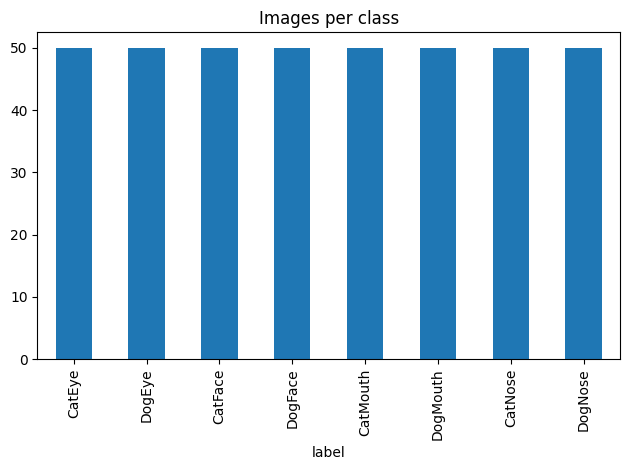

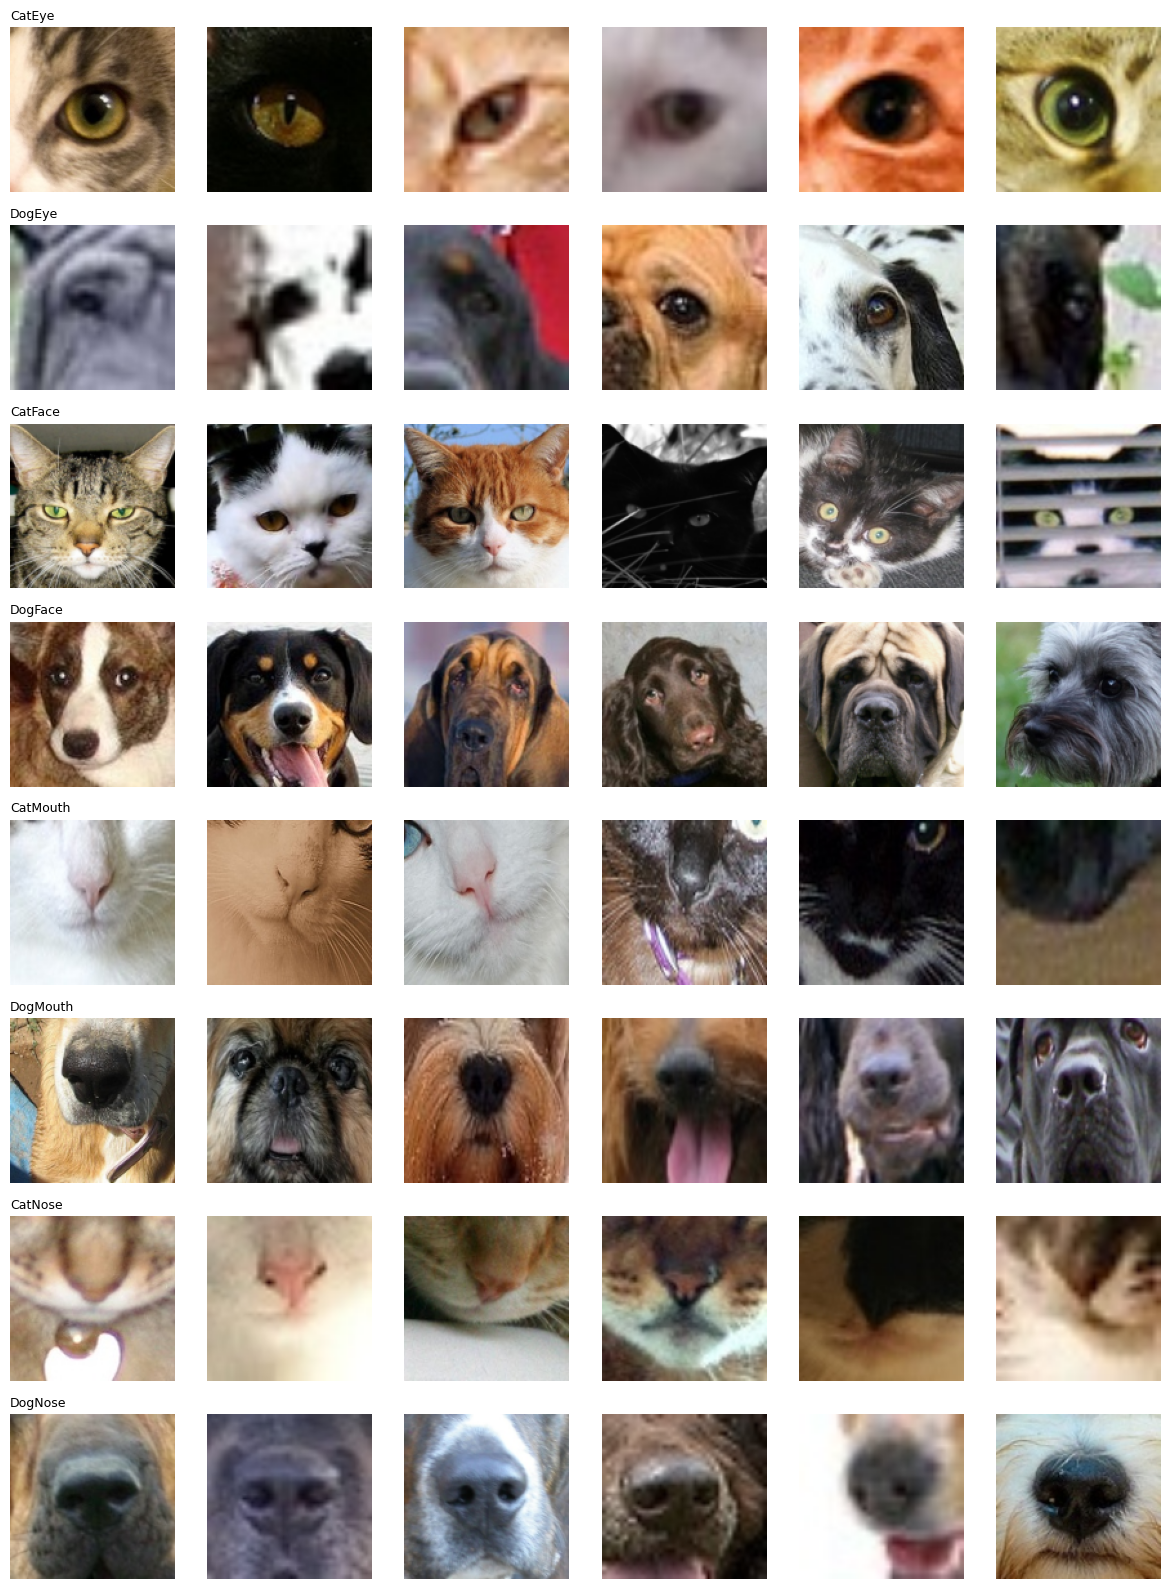

In [3]:
if DEBUG:
    train_df = train_df.groupby('label').head(50).reset_index(drop=True)
    test_paths, test_ids = test_paths[:100], test_ids[:100]

def load(p):
    try:
        raw = Path(p).read_bytes()
        im = Image.open(p); im.load()
        arr = np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        return arr, im.size[0], im.size[1], hashlib.md5(raw).hexdigest(), True
    except Exception:
        return None, 0, 0, '', False

CACHE = OUT_DIR / f"cache_{'debug' if DEBUG else 'full'}"
if CACHE.with_suffix('.npz').exists():
    z = np.load(CACHE.with_suffix('.npz')); X_all, X_test = z['X_all'], z['X_test']
    train_df = pd.read_pickle(CACHE.with_suffix('.pkl')); print('Loaded cache')
else:
    res = [load(p) for p in train_df['path']]
    train_df['w']   = [r[1] for r in res]
    train_df['h']   = [r[2] for r in res]
    train_df['md5'] = [r[3] for r in res]
    ok = np.array([r[4] for r in res], dtype=bool)
    X_all = np.stack([r[0] for r in res if r[4]])
    train_df = train_df[ok].reset_index(drop=True)
    print('Corrupted train images removed:', (~ok).sum())
    del res
    blank = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    tres = [load(p) for p in test_paths]
    print('Unreadable test images (blank placeholder used):', sum(not r[4] for r in tres))
    X_test = np.stack([r[0] if r[4] else blank for r in tres])
    del tres
    np.savez(CACHE.with_suffix('.npz'), X_all=X_all, X_test=X_test)
    train_df.to_pickle(CACHE.with_suffix('.pkl'))

train_df['y'] = train_df['label'].map({c: i for i, c in enumerate(CLASSES)})
y_all = train_df['y'].values
print('Shapes:', X_all.shape, X_test.shape)
print('Original sizes (min/mean/max):', train_df[['w', 'h']].agg(['min', 'mean', 'max']).values.tolist())
dup = train_df.duplicated('md5', keep=False)
print('Exact-duplicate images:', dup.sum(),
      '| duplicate groups with conflicting labels:', (train_df[dup].groupby('md5')['label'].nunique() > 1).sum())

train_df['label'].value_counts().reindex(CLASSES).plot.bar(title='Images per class'); plt.tight_layout()
plt.savefig(OUT_DIR / 'class_counts.png', dpi=150); plt.show()

fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx = train_df.index[train_df['label'] == c][:6]
    for k, i in enumerate(idx): axes[r, k].imshow(X_all[i]); axes[r, k].axis('off')
    axes[r, 0].set_title(c, loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / 'samples.png', dpi=120); plt.show()

In [4]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(X_all, y_all, groups=train_df['md5']))  # duplicates never straddle the split
print(f'Train {len(tr_idx)} | Val {len(va_idx)}')

to_mode = T.Grayscale(1) if CHANNELS == 1 else T.Lambda(lambda im: im)
MEAN, STD = [0.5] * CHANNELS, [0.5] * CHANNELS
train_tf = T.Compose([to_mode, T.RandomHorizontalFlip(),
                      T.RandomAffine(12, translate=(0.08, 0.08), scale=(0.9, 1.1)),
                      T.ColorJitter(brightness=0.25, contrast=0.25), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf  = T.Compose([to_mode, T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img = self.tf(Image.fromarray(self.X[i]))
        return (img, int(self.y[i])) if self.y is not None else img

nw = 2
train_dl = DataLoader(DS(X_all[tr_idx], y_all[tr_idx], train_tf), BATCH_SIZE, shuffle=True, num_workers=nw)
val_dl   = DataLoader(DS(X_all[va_idx], y_all[va_idx], eval_tf), BATCH_SIZE, num_workers=nw)

def block(cin, cout, p):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout2d(p))

class CustomCNN(nn.Module):
    def __init__(self, in_ch=1, n_classes=8):
        super().__init__()
        self.features = nn.Sequential(block(in_ch, 32, 0.05), block(32, 64, 0.10),
                                      block(64, 128, 0.15), block(128, 256, 0.20))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n_classes))  # raw logits
    def forward(self, x): return self.head(self.pool(self.features(x)))

model = CustomCNN(CHANNELS, len(CLASSES)).to(device)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_dl))

Train 320 | Val 80
Parameters: 1,174,696


In [5]:
use_amp = device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(dl, train):
    model.train(train)
    loss_sum = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return loss_sum / n, correct / n

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val, bad, ckpt = float('inf'), 0, OUT_DIR / f'{RUN_NAME}_best.pt'
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_dl, True); vl, va = run_epoch(val_dl, False)
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    print(f'Epoch {epoch:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s')
    if vl < best_val:
        best_val, bad = vl, 0; torch.save(model.state_dict(), ckpt)
    else:
        bad += 1
        if bad >= PATIENCE: print('Early stopping.'); break
json.dump(history, open(OUT_DIR / f'{RUN_NAME}_history.json', 'w'))

Epoch 01 | train loss 2.246 acc 0.103 | val loss 2.103 acc 0.175 | 33s
Epoch 02 | train loss 2.129 acc 0.141 | val loss 2.200 acc 0.175 | 33s


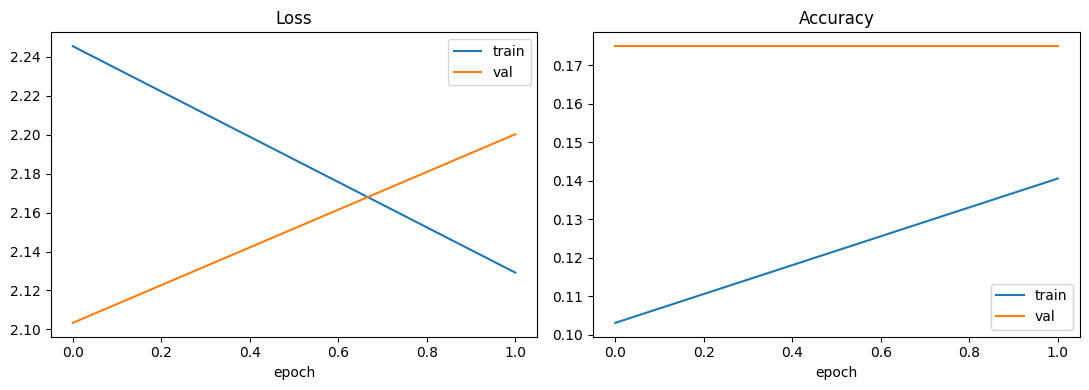

              precision    recall  f1-score   support

      CatEye      0.000     0.000     0.000         4
      DogEye      0.175     1.000     0.298        14
     CatFace      0.000     0.000     0.000        14
     DogFace      0.000     0.000     0.000        10
    CatMouth      0.000     0.000     0.000         9
    DogMouth      0.000     0.000     0.000        12
     CatNose      0.000     0.000     0.000        10
     DogNose      0.000     0.000     0.000         7

    accuracy                          0.175        80
   macro avg      0.022     0.125     0.037        80
weighted avg      0.031     0.175     0.052        80



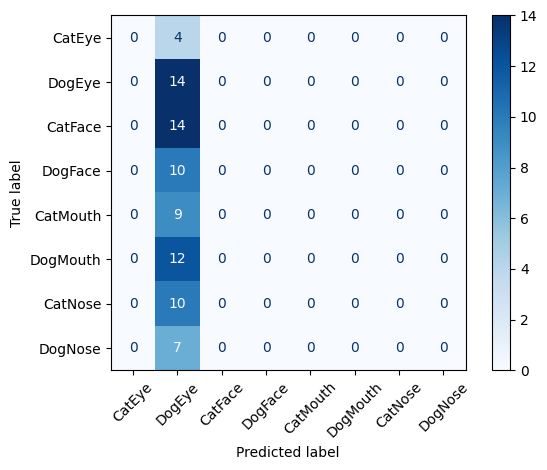

Validation accuracy: 0.175


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='val'); ax[0].set_title('Loss')
ax[1].plot(history['train_acc'], label='train');  ax[1].plot(history['val_acc'], label='val');  ax[1].set_title('Accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_curves.png', dpi=150); plt.show()

model.load_state_dict(torch.load(ckpt, map_location=device)); model.eval()
preds, trues = [], []
with torch.no_grad():
    for x, y in val_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); trues += y.tolist()
print(classification_report(trues, preds, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(trues, preds, labels=range(len(CLASSES)))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(xticks_rotation=45, cmap='Blues')
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_confusion.png', dpi=150); plt.show()
print('Validation accuracy:', np.mean(np.array(preds) == np.array(trues)))

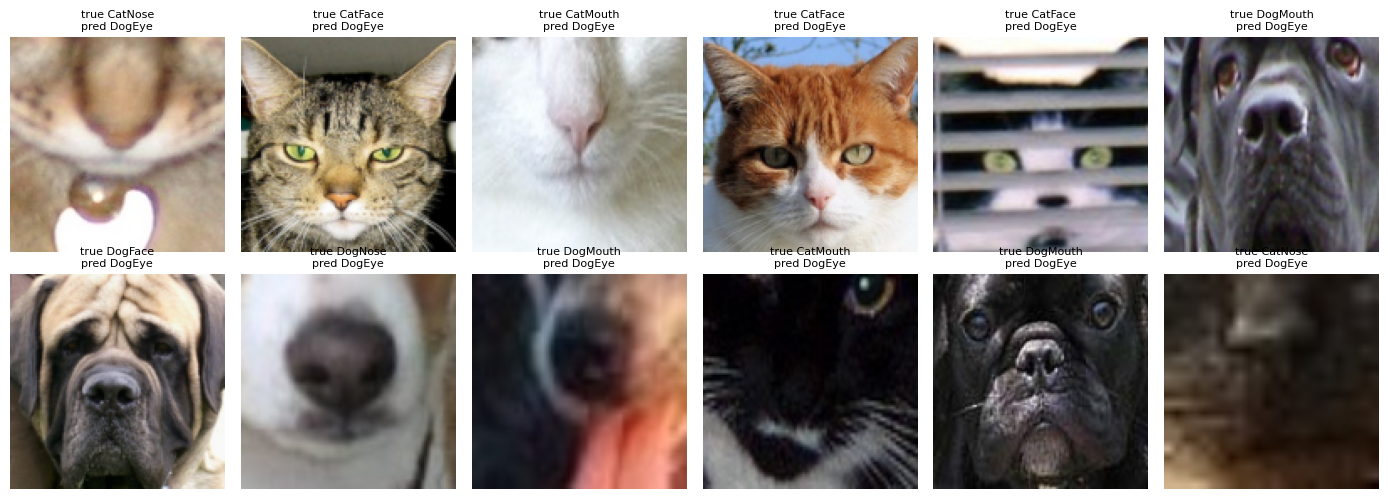

In [7]:
wrong = [i for i, (p, t) in enumerate(zip(preds, trues)) if p != t][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for a in axes.ravel(): a.axis('off')
for a, i in zip(axes.ravel(), wrong):
    a.imshow(X_all[va_idx[i]])
    a.set_title(f'true {CLASSES[trues[i]]}\npred {CLASSES[preds[i]]}', fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / f'{RUN_NAME}_errors.png', dpi=120); plt.show()

In [8]:
test_dl = DataLoader(DS(X_test, None, eval_tf), BATCH_SIZE, num_workers=nw)
probs = []
with torch.no_grad():
    for x in test_dl:
        x = x.to(device)
        probs.append((model(x).softmax(1) + model(torch.flip(x, dims=[3])).softmax(1)).cpu())  # flip TTA
test_pred = torch.cat(probs).argmax(1).numpy()

# Use the exact class spelling found in train_labels.csv (e.g. DogEye vs DogEyes)
raw = pd.read_csv(label_csv, dtype=str)
ccol = 'class' if 'class' in raw.columns else raw.columns[-1]
spelling = {CANON[norm(s)]: s for s in raw[ccol].unique()}
print('Spelling used in train_labels.csv:', spelling)

sub = pd.DataFrame({'image_id': test_ids, 'class': [spelling[CLASSES[i]] for i in test_pred]})
sub_path = OUT_DIR / ('submission_debug.csv' if DEBUG else 'submission.csv')
sub.to_csv(sub_path, index=False)
print(sub.head(), '\nRows:', len(sub), '| saved to', sub_path)
if sample_sub is not None:
    print('Sample submission head:\n', pd.read_csv(sample_sub, dtype=str).head(3))

Spelling used in train_labels.csv: {'DogEye': 'DogEye', 'DogMouth': 'DogMouth', 'DogFace': 'DogFace', 'DogNose': 'DogNose', 'CatNose': 'CatNose', 'CatFace': 'CatFace', 'CatMouth': 'CatMouth', 'CatEye': 'CatEye'}
  image_id   class
0    10000  DogEye
1    10001  DogEye
2    10002  DogEye
3    10003  DogEye
4    10004  DogEye 
Rows: 100 | saved to /kaggle/working/submission_debug.csv
Sample submission head:
   image_id    class
0        1   DogEye
1        2  CatNose
2        3  CatNose
